# Project 2: Credit Card Fraud Detection as an Anomaly Ranking Problem
## Charles MUGANGA B35391
DSC8307 Data Mining, Modeling and Analytics. Advent 2026 Assignment 2.

## What this notebook does

A card company cannot check every transaction by hand, so it needs a way to put the most suspicious ones at the top of an investigator's queue. In this notebook I am building and comparing detectors that rank transactions by how likely they are to need investigation, and then checking that ranking against the fraud labels, which I keep hidden from the detectors except where a method is explicitly allowed to learn from past labels. I am working through the three tasks in the assignment:

1. Exploring the data, writing a short report on it, preparing it with a reason for every step, and setting up a statistical outlier baseline.
2. Comparing a cluster based approach and a classification based approach, and justifying each choice.
3. Explaining, with evidence from this data, why an unusual transaction is not necessarily a fraudulent one.

The notebook runs from top to bottom with the packages in `requirements.txt`. The original file is 150 MB, which is too large for a normal GitHub upload, so I have stored it in the `data/creditcard` folder as four compressed parts. The notebook joins them back together and checks that nothing was lost. I am using one random seed throughout so the numbers in the text match the outputs.

In [ ]:
# importing the libraries I need for data handling, modelling, evaluation and plotting
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import MinCovDet
from sklearn.cluster import KMeans
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDOneClassSVM, LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             silhouette_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)

# fixing one random seed here so that every split, sample and model gives the same answer each time
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## Part 1. Understanding the data

### 1.1 Loading the four parts and checking them

The data was released by the Machine Learning Group of the Université Libre de Bruxelles together with Worldline (Dal Pozzolo and colleagues, 2015). Because of confidentiality, 28 of the 30 inputs (V1 to V28) are principal components of the original, unpublished features. Only `Time` (seconds since the first transaction) and `Amount` (in euros) are in their original form. `Class` is 1 for fraud and 0 otherwise.

In [2]:
# Joining the four compressed parts back into one table and checking it against the figures in the README
parts = sorted(glob.glob("data/creditcard/creditcard_part*.csv.gz"))
raw = pd.concat([pd.read_csv(p) for p in parts], ignore_index=True)
print("Parts read:", [p.split("/")[-1] for p in parts])
print("Rows and columns:", raw.shape)
print("Frauds:", int(raw["Class"].sum()), " fraud share:", round(raw["Class"].mean() * 100, 3), "percent")
assert raw.shape == (284807, 31) and raw["Class"].sum() == 492, "the rebuilt file does not match the README"
print("Missing values:", int(raw.isna().sum().sum()))
raw.head()

Parts read: ['creditcard_part1.csv.gz', 'creditcard_part2.csv.gz', 'creditcard_part3.csv.gz', 'creditcard_part4.csv.gz']
Rows and columns: (284807, 31)
Frauds: 492  fraud share: 0.173 percent
Missing values: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


The rebuilt table has exactly the 284,807 transactions and 492 frauds the README describes, and no missing values. Fraud makes up only 0.173 percent of transactions, roughly one in 580.

### 1.2 Time: two days of transactions

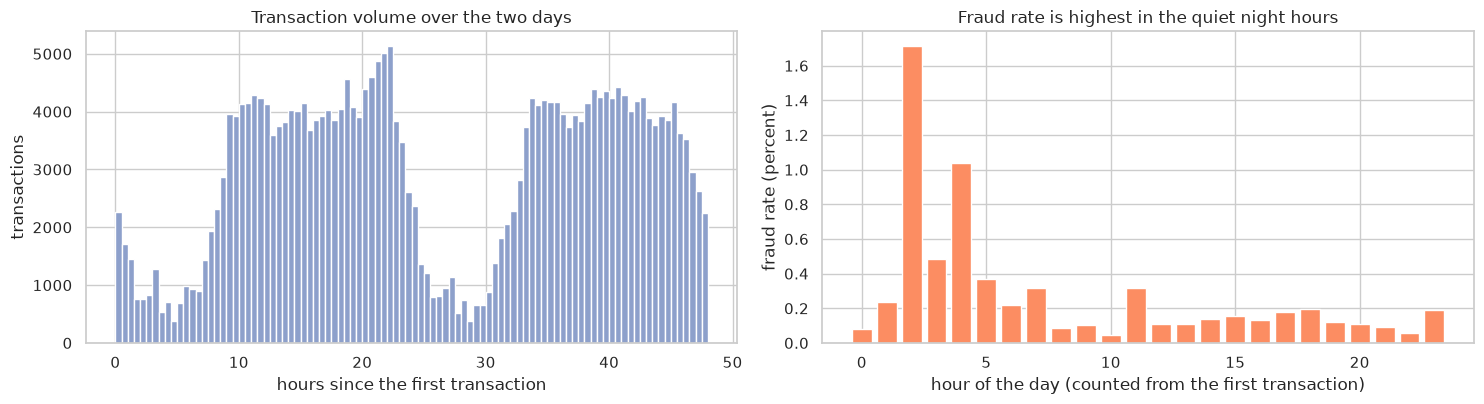

hour_of_day             0.0       1.0       2.0       3.0       4.0       5.0       6.0       7.0        8.0        9.0        10.0       11.0  \
size                7695.000  4220.000  3328.000  3492.000  2209.000  2990.000  4101.000  7243.000  10276.000  15838.000  16598.000  16856.000   
fraud_rate_percent     0.078     0.237     1.713     0.487     1.041     0.368     0.219     0.318      0.088      0.101      0.048      0.314   

hour_of_day             12.0       13.0       14.0       15.0       16.0       17.0       18.0       19.0       20.0      21.0       22.0       23.0  
size                15420.00  15365.000  16570.000  16461.000  16453.000  16166.000  17039.000  15649.000  16756.000  17703.00  15441.000  10938.000  
fraud_rate_percent      0.11      0.111      0.139      0.158      0.134      0.179      0.194      0.121      0.107      0.09      0.058      0.192  


In [3]:
# Turning seconds into hours since the start and into the hour of the day, then plotting volume and fraud rate
raw["hours_since_start"] = raw["Time"] / 3600
raw["hour_of_day"] = (raw["Time"] % 86400) // 3600

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
axes[0].hist(raw["hours_since_start"], bins=96, color="#8da0cb")
axes[0].set(xlabel="hours since the first transaction", ylabel="transactions", title="Transaction volume over the two days")
by_hour = raw.groupby("hour_of_day")["Class"].agg(["mean", "size"])
axes[1].bar(by_hour.index, by_hour["mean"] * 100, color="#fc8d62")
axes[1].set(xlabel="hour of the day (counted from the first transaction)", ylabel="fraud rate (percent)",
            title="Fraud rate is highest in the quiet night hours")
plt.tight_layout(); plt.show()
print(by_hour.assign(fraud_rate_percent=lambda d: (d["mean"] * 100).round(3)).drop(columns="mean").T)

Transaction volume follows a clear daily cycle, with two busy daytime periods separated by a quiet night. The hour labels count from the first transaction, whose real clock time is not given, but the quiet period is almost certainly night time. The fraud rate behaves the opposite way: in the quietest hours (hour 2 in this counting) about 1.7 percent of transactions are fraudulent, roughly ten times the overall rate. Fraud does not stop at night but legitimate spending does, so fraud makes up a much larger share of what remains.

### 1.3 Transaction amounts

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87

Transactions with an amount of zero: 1825  of which fraud: 27


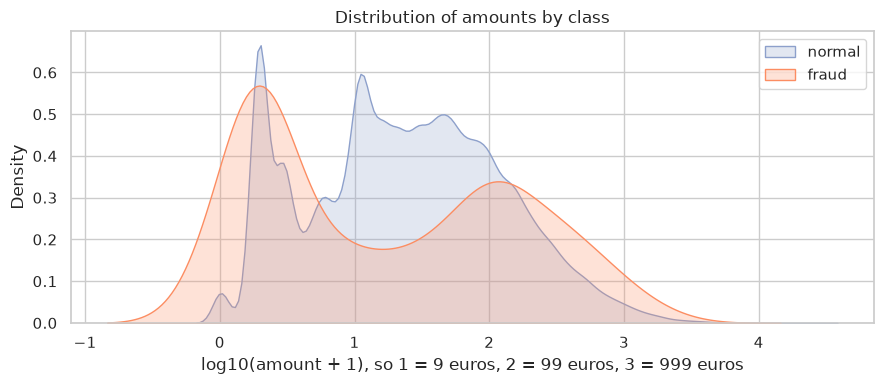

In [4]:
# Comparing amounts for normal and fraudulent transactions, on a log scale because amounts are very skewed
print(raw.groupby("Class")["Amount"].describe().round(2))
print("\nTransactions with an amount of zero:", int((raw["Amount"] == 0).sum()),
      " of which fraud:", int(raw.loc[raw["Amount"] == 0, "Class"].sum()))

fig, ax = plt.subplots(figsize=(9, 4))
for cls, col, lab in [(0, "#8da0cb", "normal"), (1, "#fc8d62", "fraud")]:
    sns.kdeplot(np.log10(raw.loc[raw["Class"] == cls, "Amount"] + 1), ax=ax, fill=True, color=col, label=lab, common_norm=False)
ax.set(xlabel="log10(amount + 1), so 1 = 9 euros, 2 = 99 euros, 3 = 999 euros", title="Distribution of amounts by class")
ax.legend(); plt.tight_layout(); plt.show()

Amounts are very skewed: the median transaction is 22 euros but the largest is over 25,000 euros. Fraudulent transactions are not unusually large. Their median is only 9.25 euros, lower than for normal transactions, and a quarter of them are 1 euro or less. A well known explanation is that fraudsters often test a stolen card with small payments before attempting larger ones. The largest fraud in the data is about 2,126 euros, while many legitimate payments are far bigger. So a simple rule such as "flag large amounts" would point investigators the wrong way. I come back to this in Part 3.

### 1.4 The anonymised features

In [5]:
# Checking the spread of each principal component and how correlated they are with each other
v_cols = [f"V{i}" for i in range(1, 29)]
spread = raw[v_cols].std()
corr_v = raw[v_cols].corr().to_numpy()
off_diag = np.abs(corr_v[~np.eye(28, dtype=bool)])
print("Standard deviation of V1 falls to V28:", round(spread.iloc[0], 2), "to", round(spread.iloc[-1], 2))
print("Largest absolute correlation between any two V columns:", round(off_diag.max(), 4))

# Ranking the components by how far the fraud mean sits from the normal mean, in normal standard deviations
gap = ((raw.loc[raw.Class == 1, v_cols].mean() - raw.loc[raw.Class == 0, v_cols].mean()) /
       raw.loc[raw.Class == 0, v_cols].std()).sort_values(key=np.abs, ascending=False)
gap.round(2).head(10).to_frame("standardised mean gap (fraud minus normal)")

Standard deviation of V1 falls to V28: 1.96 to 0.33
Largest absolute correlation between any two V columns: 0.0


,standardised mean gap (fraud minus normal)
V17,-8.91
V14,-7.79
V12,-6.63
V10,-5.45
V16,-4.91
V3,-4.83
V7,-4.73
V11,3.79
V4,3.25
V18,-2.73


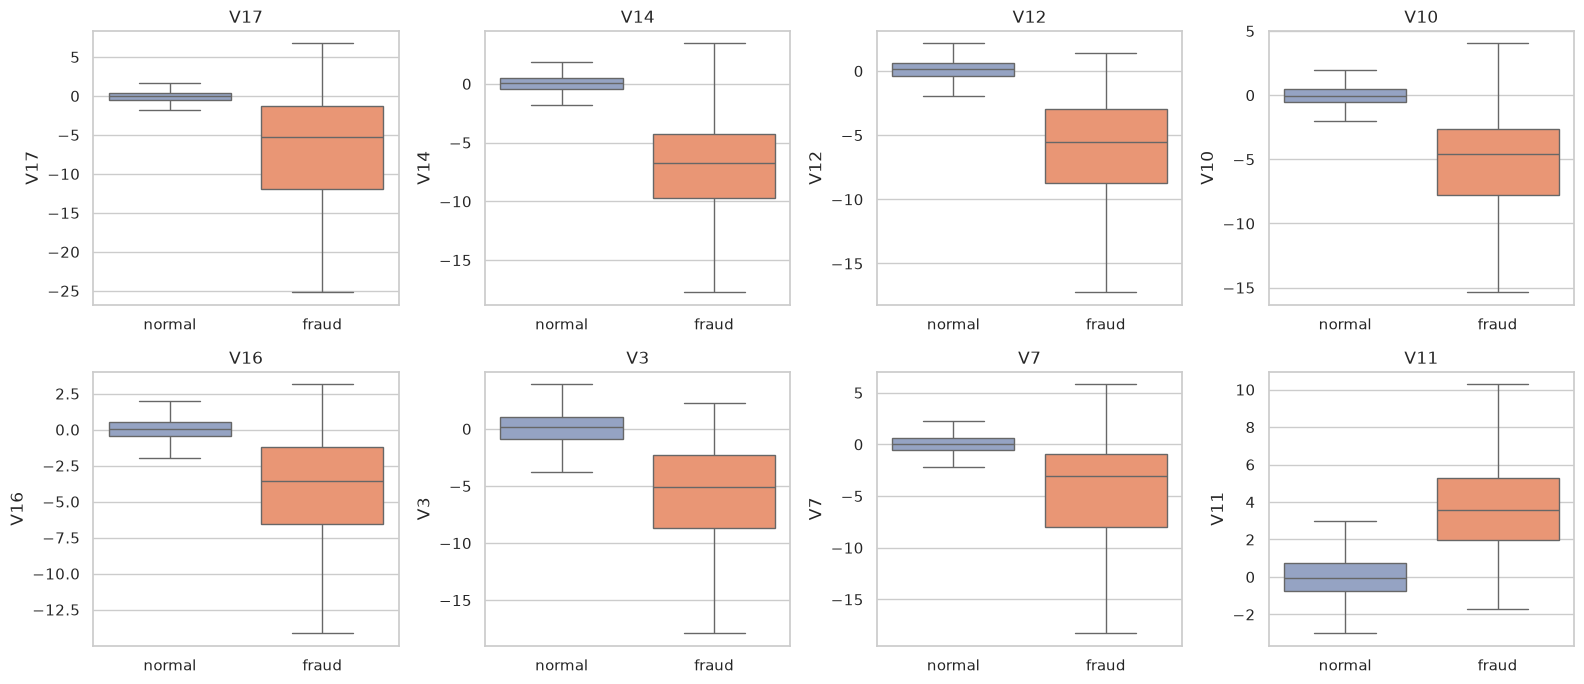

In [6]:
# Showing the eight components that separate fraud most clearly
top8 = gap.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), top8):
    sns.boxplot(data=raw, x="Class", y=col, ax=ax, showfliers=False, palette=["#8da0cb", "#fc8d62"])
    ax.set(title=col, xlabel="", xticks=[0, 1], xticklabels=["normal", "fraud"])
plt.tight_layout(); plt.show()

The V columns behave like principal components should. Their standard deviations fall steadily from V1 (about 1.96) to V28 (about 0.33), and they are uncorrelated with each other (the largest correlation between any pair is effectively zero). Several components separate fraud strongly. On V17, V14, V12, V10, V16, V3 and V7 the average fraud sits between about 4.7 and 8.9 normal standard deviations below the average normal transaction, and on V11 and V4 it sits about 3 to 4 standard deviations above. Fraud is therefore unusual in particular directions, which is encouraging for anomaly detection. Because the features are anonymised, however, we cannot say what any of these directions means in business terms.

### 1.5 Duplicates

In [7]:
# Counting exact duplicate transactions, which share every value including the time
dups = raw.duplicated(subset=["Time"] + v_cols + ["Amount", "Class"])
print("Exact duplicate rows:", int(dups.sum()), " of which fraud:", int(raw.loc[dups, "Class"].sum()))

Exact duplicate rows: 1081  of which fraud: 19


There are 1,081 rows that are exact copies of an earlier row, including 19 frauds. Two genuinely separate card payments matching on time to the second and on all 30 numeric values is very unlikely, so these are probably repeated records, for example from a resubmitted transaction.

### 1.6 Short report on the data

The dataset holds 284,807 card transactions made by European cardholders over two days in September 2013, of which 492 (0.173 percent) are labelled fraud. Inputs are 28 anonymised principal components, the time in seconds since the first transaction and the amount in euros. There are no missing values.

Its main limitations are these. The extreme imbalance makes accuracy meaningless (calling everything normal is 99.83 percent accurate), so ranking metrics such as precision at a fixed review budget and the area under the precision recall curve are needed (Saito and Rehmsmeier, 2015). The features are anonymised, so no business meaning can be attached to them, and customer history, merchant and location are missing although they matter greatly for fraud. The principal components were computed by the data owners on the full dataset, so a small amount of information about the later transactions is already built into the features, which no split can remove. Two days is a very short window, so weekly patterns and changes in fraud tactics are invisible. Labels reflect fraud that was detected and reported, so some fraud may be hidden among the "normal" transactions. Finally, there are 1,081 duplicate rows.

The exploration shows that fraud is concentrated in the quiet night hours, is typically small rather than large in amount, and is extreme along a handful of the principal components.

## Part 1 (continued). Data preparation

1. I am removing the 1,081 exact duplicate rows so the same record cannot be counted twice or appear on both sides of the split.
2. I am replacing `Amount` with log(1 + amount). Amounts are extremely skewed, and on the raw scale a handful of very large legitimate payments would dominate every distance based method.
3. I am not using `Time` as a model input in the main analysis. Its raw value only says how far into the two day window a transaction happened, which would not carry over to a future period. I use it to order the data for the split, and section 2.5 checks whether adding the hour of the day helps.
4. I am splitting the data in time order. The detectors are built on the earliest 70 percent of transactions and evaluated on the most recent 30 percent, which imitates real use, where a model built on the past ranks the transactions that come next.
5. I am standardising every input using the mean and standard deviation of the training period only, so that nothing about the test period leaks into the preparation. The V columns already have mean zero but different spreads, and standardising puts them on an equal footing for distance based methods.
6. I am keeping the test labels hidden from every method. The statistical baseline and the cluster based method never see any labels at all. The classification based methods may learn from the labels of the training period only, as a real fraud team would learn from past confirmed cases.

In [8]:
# Steps 1 and 2: dropping duplicates and log transforming the amount
df = raw.loc[~dups].copy()
df["log_amount"] = np.log1p(df["Amount"])
features = v_cols + ["log_amount"]

# Step 4: sorting by time and cutting at 70 percent
df = df.sort_values("Time", kind="stable").reset_index(drop=True)
cut = int(len(df) * 0.7)
train, test = df.iloc[:cut].copy(), df.iloc[cut:].copy()
print(f"Training period: {len(train):,} transactions, {int(train.Class.sum())} frauds, ends at hour {train.hours_since_start.max():.1f}")
print(f"Test period:     {len(test):,} transactions, {int(test.Class.sum())} frauds, from hour {test.hours_since_start.min():.1f}")

# Step 5: standardising with training statistics only
scaler = StandardScaler().fit(train[features])
X_train, X_test = scaler.transform(train[features]), scaler.transform(test[features])
y_train, y_test = train["Class"].to_numpy(), test["Class"].to_numpy()

Training period: 198,608 transactions, 366 frauds, ends at hour 36.9
Test period:     85,118 transactions, 107 frauds, from hour 36.9


### 1.7 How the rankings will be judged

An investigation team works down a list from the top, so what matters is how many real frauds appear near the top. I am using the following measures, all calculated on the test period:

1. Average precision (AP), the area under the precision recall curve. A random ranking scores the fraud rate, about 0.0013 here, and a perfect ranking scores 1.
2. ROC AUC, the chance that a random fraud is ranked above a random normal transaction. It is reported for completeness but can look flattering when fraud is this rare.
3. Frauds found within a fixed review budget: how many of the top 100, 500 and 1,000 ranked transactions are real frauds, and what share of all test frauds that represents. With about 85,000 test transactions over roughly 11 hours, reviewing 100 is a small team's workload and 1,000 is a large one.

In [9]:
def ranking_report(name, scores, y=None):
    """Summarising how well a set of scores ranks the frauds, with higher scores meaning more suspicious."""
    y = y_test if y is None else y
    order = np.argsort(-scores, kind="stable")
    row = {"method": name, "AP": average_precision_score(y, scores), "ROC AUC": roc_auc_score(y, scores)}
    for k in [100, 500, 1000]:
        hits = int(y[order[:k]].sum())
        row[f"frauds in top {k}"] = hits
        row[f"recall at {k}"] = hits / y.sum()
    return row

random_scores = rng.random(len(y_test))
results = [ranking_report("Random ordering (no model)", random_scores)]
pd.DataFrame(results).set_index("method").round(4)

,AP,ROC AUC,frauds in top 100,recall at 100,frauds in top 500,recall at 500,frauds in top 1000,recall at 1000
method,,,,,,,,
Random ordering (no model),0.0013,0.5119,0,0.0,0,0.0,0,0.0


### 1.8 Statistical outlier baseline

The classic statistical way to find outliers in many dimensions is the Mahalanobis distance (Mahalanobis, 1936). It measures how far a transaction is from the centre of the data, allowing for the spread and correlation of each variable. If the data were multivariate normal, the squared distance would follow a chi squared distribution with as many degrees of freedom as there are inputs (29 here), which gives a formal test for outliers. Because the V columns are uncorrelated principal components, this distance is close to the sum of squared standardised values, which is a natural "how extreme is this transaction overall" score.

I am also trying two variants: a robust version using the minimum covariance determinant (Rousseeuw and Van Driessen, 1999), which estimates the centre and spread from the most typical 50 to 100 percent of points so that outliers cannot distort them, and a simple score that adds up squared robust z scores (based on the median and median absolute deviation). All three are fitted on the training period without labels.

In [10]:
# Classic Mahalanobis distance, fitted on the training period without labels
centre = X_train.mean(axis=0)
precision_matrix = np.linalg.pinv(np.cov(X_train, rowvar=False))
diff = X_test - centre
maha_test = np.einsum("ij,jk,ik->i", diff, precision_matrix, diff)

# Robust Mahalanobis distance, with the robust centre and spread estimated on a sample of 20,000 training transactions
mcd = MinCovDet(random_state=RANDOM_STATE).fit(X_train[rng.choice(len(X_train), 20000, replace=False)])
maha_robust_test = mcd.mahalanobis(X_test)

# Sum of squared robust z scores, using the median and the median absolute deviation of the training period
med = np.median(X_train, axis=0)
mad = 1.4826 * np.median(np.abs(X_train - med), axis=0)
robust_z_test = (((X_test - med) / mad) ** 2).sum(axis=1)

for name, s in [("Statistical: Mahalanobis distance", maha_test),
                ("Statistical: robust Mahalanobis (MCD)", maha_robust_test),
                ("Statistical: sum of squared robust z", robust_z_test)]:
    results.append(ranking_report(name, s))
pd.DataFrame(results).set_index("method").round(4)

,AP,ROC AUC,frauds in top 100,recall at 100,frauds in top 500,recall at 500,frauds in top 1000,recall at 1000
method,,,,,,,,
Random ordering (no model),0.0013,0.5119,0,0.0000,0,0.0000,0,0.0000
Statistical: Mahalanobis distance,0.0356,0.9457,0,0.0000,19,0.1776,57,0.5327
Statistical: robust Mahalanobis (MCD),0.0288,0.8968,1,0.0093,16,0.1495,43,0.4019
Statistical: sum of squared robust z,0.0168,0.9261,0,0.0000,1,0.0093,10,0.0935


In [11]:
# Applying the formal chi squared test: how many test transactions would be flagged at different significance levels?
df_chi = len(features)
flag_rows = []
for alpha in [0.01, 0.001, 0.0001]:
    threshold = stats.chi2.ppf(1 - alpha, df_chi)
    flagged = maha_test > threshold
    flag_rows.append({"significance level": alpha, "distance threshold": threshold, "transactions flagged": int(flagged.sum()),
                      "share flagged": flagged.mean(), "frauds among flagged": int(y_test[flagged].sum()),
                      "precision": y_test[flagged].mean(), "recall": y_test[flagged].sum() / y_test.sum()})
pd.DataFrame(flag_rows).round(4)

,significance level,distance threshold,transactions flagged,share flagged,frauds among flagged,precision,recall
0,0.0100,49.5879,6004,0.0705,93,0.0155,0.8692
1,0.0010,58.3012,4368,0.0513,90,0.0206,0.8411
2,0.0001,66.1517,3561,0.0418,89,0.0250,0.8318


The classic Mahalanobis distance is a meaningful baseline. Its ROC AUC of about 0.95 shows that frauds are, on the whole, far more extreme than normal transactions. Its average precision is only about 0.04, however, and its top 100 transactions contain no frauds at all. The most extreme transactions in the test period are not frauds.

The formal chi squared test also shows that the normal model does not fit. If the data were multivariate normal, a 0.1 percent significance level would flag about 0.1 percent of transactions, around 85. Instead it flags several thousand, because the V columns have much heavier tails than a normal distribution. A test based on normality is therefore unsuitable for setting an alert threshold here, although the distance is still useful for ranking.

Surprisingly, the robust versions do worse. By design they estimate the spread from the most typical transactions, which makes them shrink the spread estimates and treat every heavy tailed value as extremely unusual, so legitimate but slightly unusual transactions crowd the top of the list. This is a useful reminder that a method being "robust" in theory does not guarantee it is better for a specific task. I am using the classic Mahalanobis distance as the statistical baseline.

## Part 2. Cluster based and classification based detection

### 2.1 Why these two kinds of approach

Han, Kamber and Pei (2011) group outlier detection methods into statistical, proximity based, clustering based and classification based approaches. The two asked for here rest on different assumptions and need different information.

A cluster based detector assumes that normal transactions form groups and that anomalies either sit far from every group or form very small groups of their own. Its main advantage is that it needs no labels at all, so it can be used from the first day and can, in principle, notice a new kind of fraud nobody has seen before. I am using k means to find the groups and scoring each transaction by its distance to the nearest cluster centre, and I am also trying the cluster based local outlier factor idea of He, Xu and Deng (2003), which treats members of very small clusters as anomalous.

A classification based detector learns the boundary between normal and fraudulent behaviour from labelled examples. A card company does have labels for past transactions, because customers report fraud and chargebacks confirm it, so it is realistic to train on the labelled history and rank new transactions. I am trying two versions. A one class support vector machine (Schölkopf and colleagues, 2001) learns the boundary of normal behaviour from transactions known to be normal, and treats anything outside it as suspicious. Supervised classifiers (logistic regression and gradient boosting) learn directly from both normal and fraud examples.

The trade off is clear in advance: the classification based approach should rank known kinds of fraud far better, because it is told what fraud looks like, while the cluster based approach asks for nothing and is therefore more general but less targeted.

### 2.2 Cluster based detection with k means

The number of clusters has to be chosen without looking at the labels, otherwise the method would no longer be unsupervised. I am choosing it with the silhouette coefficient on a random sample of 10,000 training transactions, which is enough for a stable estimate and keeps the computation manageable.

In [12]:
# Choosing the number of clusters by silhouette on a training sample, with no labels involved
sample_idx = rng.choice(len(X_train), 10000, replace=False)
sil_rows, km_models = [], {}
for k in [2, 3, 4, 5, 6, 8, 10, 12, 15, 20]:
    km = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE).fit(X_train)
    km_models[k] = km
    sizes = np.bincount(km.labels_) / len(km.labels_)
    sil_rows.append({"k": k, "silhouette (sample)": silhouette_score(X_train[sample_idx], km.labels_[sample_idx]),
                     "smallest cluster share": sizes.min(), "largest cluster share": sizes.max()})
sil_table = pd.DataFrame(sil_rows).set_index("k")
best_k = int(sil_table["silhouette (sample)"].idxmax())
print("Number of clusters chosen by silhouette:", best_k)
sil_table.round(4)

Number of clusters chosen by silhouette: 15


,silhouette (sample),smallest cluster share,largest cluster share
k,,,
2,0.0584,0.4182,0.5818
3,0.0613,0.1567,0.5195
4,0.0330,0.1013,0.3713
5,0.0567,0.0011,0.4114
6,0.0710,0.0011,0.4612
8,0.0416,0.0011,0.2698
10,0.0715,0.0011,0.2481
12,0.0580,0.0011,0.2072
15,0.0724,0.0011,0.1610


Every silhouette value is below 0.1, which means the transactions do not form well separated groups. This is not a surprise: the V columns are principal components, which spread the data into one large, roughly elliptical cloud. The highest silhouette is at the k shown above, so I am using that number, but the low values already warn that a method built on the idea of distinct groups is working against the grain of this data.

In [13]:
# Scoring each test transaction by its distance to the nearest centre, and with the CBLOF idea:
# a transaction in a small cluster (under 5 percent of training data) is scored by its distance to the nearest large cluster
km = km_models[best_k]
dist_test = km.transform(X_test)
nearest_dist = dist_test.min(axis=1)
sizes = np.bincount(km.labels_, minlength=best_k) / len(km.labels_)
large = sizes >= 0.05
assigned = km.predict(X_test)
cblof = np.where(large[assigned], dist_test[np.arange(len(X_test)), assigned], dist_test[:, large].min(axis=1))

results.append(ranking_report(f"Cluster based: k means distance (k = {best_k})", nearest_dist))
results.append(ranking_report(f"Cluster based: CBLOF style (k = {best_k})", cblof))
pd.DataFrame(results).set_index("method").round(4)

,AP,ROC AUC,frauds in top 100,recall at 100,frauds in top 500,recall at 500,frauds in top 1000,recall at 1000
method,,,,,,,,
Random ordering (no model),0.0013,0.5119,0,0.0000,0,0.0000,0,0.0000
Statistical: Mahalanobis distance,0.0356,0.9457,0,0.0000,19,0.1776,57,0.5327
Statistical: robust Mahalanobis (MCD),0.0288,0.8968,1,0.0093,16,0.1495,43,0.4019
Statistical: sum of squared robust z,0.0168,0.9261,0,0.0000,1,0.0093,10,0.0935
Cluster based: k means distance (k = 15),0.0479,0.9408,0,0.0000,44,0.4112,61,0.5701
Cluster based: CBLOF style (k = 15),0.0402,0.9505,0,0.0000,21,0.1963,58,0.5421


The distance based cluster scores do little better than the statistical baseline. To understand why, I am opening up the clusters themselves. The training labels are used here only to explain the result after the fact, never to build or tune the detector.

In [14]:
# Diagnosing the clusters: how big is each one, and how much fraud did it turn out to contain?
diag = pd.DataFrame({"cluster": km.labels_, "fraud": y_train, "amount": train["Amount"].to_numpy()})
diag = diag.groupby("cluster").agg(transactions=("fraud", "size"), frauds=("fraud", "sum"),
                                   fraud_rate=("fraud", "mean"), median_amount=("amount", "median"))
diag["share of training data"] = diag["transactions"] / len(y_train)
diag["share of all training frauds"] = diag["frauds"] / y_train.sum()
diag.sort_values("transactions").round(4)

,transactions,frauds,fraud_rate,median_amount,share of training data,share of all training frauds
cluster,,,,,,
3,212,172,0.8113,59.340,0.0011,0.4699
14,455,4,0.0088,15.000,0.0023,0.0109
13,983,3,0.0031,74.000,0.0049,0.0082
7,1771,0,0.0000,3.780,0.0089,0.0000
10,3017,71,0.0235,1.790,0.0152,0.1940
5,3328,9,0.0027,1107.405,0.0168,0.0246
2,7462,0,0.0000,36.850,0.0376,0.0000
8,11723,0,0.0000,21.000,0.0590,0.0000
4,11825,4,0.0003,78.010,0.0595,0.0109


This table is one of the most interesting results in the notebook. Without seeing a single label, k means has formed one tiny cluster holding about 0.1 percent of the training transactions, and around 80 percent of its members turn out to be fraud. That one cluster contains close to half of all the training frauds. So fraud in this data is not just scattered far from the centre. A large part of it forms a small, tight group of its own.

The distance score cannot use this, because members of that small cluster sit close to their own centre and therefore get low distance scores. This is exactly the situation that He, Xu and Deng (2003) had in mind when they defined cluster based outliers: points that belong to small clusters are anomalous because their cluster is rare, not because they are far from it. So I am adding a third cluster based score built directly on that definition, cluster rarity. Each transaction is scored by how rare its cluster is (minus the log of the cluster's share of the training data), and distance to the centre is only used to break ties within a cluster. This score still uses no labels. Section 2.5 checks that its advantage is not tied to one particular k.

In [15]:
# Cluster rarity score: rarer clusters are more suspicious, and distance only breaks ties within a cluster
def rarity_score(model, data_train_labels, data_test):
    share = np.bincount(data_train_labels, minlength=model.n_clusters) / len(data_train_labels)
    d = model.transform(data_test)
    lab = d.argmin(axis=1)
    dist = d.min(axis=1)
    return -np.log(share[lab]) + 1e-3 * dist / dist.max()

rarity = rarity_score(km, km.labels_, X_test)
results.append(ranking_report(f"Cluster based: cluster rarity (k = {best_k})", rarity))
test_in_fraud_cluster = assigned == diag["fraud_rate"].idxmax()
print(f"Test transactions falling in the fraud rich cluster: {int(test_in_fraud_cluster.sum())}, "
      f"of which fraud: {int(y_test[test_in_fraud_cluster].sum())} out of {int(y_test.sum())} test frauds")
pd.DataFrame(results).set_index("method").round(4)

Test transactions falling in the fraud rich cluster: 10, of which fraud: 10 out of 107 test frauds


,AP,ROC AUC,frauds in top 100,recall at 100,frauds in top 500,recall at 500,frauds in top 1000,recall at 1000
method,,,,,,,,
Random ordering (no model),0.0013,0.5119,0,0.0000,0,0.0000,0,0.0000
Statistical: Mahalanobis distance,0.0356,0.9457,0,0.0000,19,0.1776,57,0.5327
Statistical: robust Mahalanobis (MCD),0.0288,0.8968,1,0.0093,16,0.1495,43,0.4019
Statistical: sum of squared robust z,0.0168,0.9261,0,0.0000,1,0.0093,10,0.0935
Cluster based: k means distance (k = 15),0.0479,0.9408,0,0.0000,44,0.4112,61,0.5701
Cluster based: CBLOF style (k = 15),0.0402,0.9505,0,0.0000,21,0.1963,58,0.5421
Cluster based: cluster rarity (k = 15),0.1093,0.8364,11,0.1028,14,0.1308,14,0.1308


The three cluster based scores behave quite differently.

The distance to the nearest centre behaves much like the statistical baseline: a high ROC AUC (about 0.94) but a low AP (about 0.05) and no frauds in its top 100. It does find more frauds within a budget of 500 (44 against 19 for the baseline), but its very top is still filled with extreme legitimate transactions. The CBLOF style variant is slightly worse, because several of the small clusters it treats as suspicious are made of unusual but legitimate transactions, such as the cluster of large payments with a median of about 1,100 euros.

Cluster rarity more than doubles the AP of the distance score (about 0.11 against 0.05) and is the only unsupervised method with real frauds at the very top of its list: 11 of its top 100 are fraud. Its weakness shows in the line printed above. Only 10 test transactions land in the fraud rich cluster, and every one of them is fraud, but that is just 10 of the 107 test frauds, whereas the same cluster held almost half of the training frauds. The kind of fraud that dominated the earlier period, probably one specific attack pattern, was much less common in the test period. Once the rare clusters are used up, the rarity score has little to say about the remaining frauds, which is why its ROC AUC (about 0.84) is lower than the distance score's.

### 2.3 Classification based detection

In [16]:
# One class SVM trained only on normal transactions from the training period. To keep it fast on this many rows
# I am approximating the RBF kernel with 300 Nystroem features and fitting a linear one class SVM on top.
normal_train = X_train[y_train == 0]
ocsvm_sample = normal_train[rng.choice(len(normal_train), 50000, replace=False)]
ocsvm = make_pipeline(Nystroem(gamma=1 / len(features), n_components=300, random_state=RANDOM_STATE),
                      SGDOneClassSVM(nu=0.01, random_state=RANDOM_STATE)).fit(ocsvm_sample)
ocsvm_scores = -ocsvm.decision_function(X_test)      # flipping the sign so that higher means more suspicious
results.append(ranking_report("Classification based: one class SVM (normal only)", ocsvm_scores))

In [17]:
# Supervised classifiers, tuned with stratified cross validation on the training period only, choosing settings by AP
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

logit_search = GridSearchCV(LogisticRegression(max_iter=3000), {"C": [0.01, 0.1, 1.0]},
                            scoring="average_precision", cv=cv).fit(X_train, y_train)
gb_search = GridSearchCV(HistGradientBoostingClassifier(max_iter=300, early_stopping=False, l2_regularization=1.0,
                                                        random_state=RANDOM_STATE),
                         {"learning_rate": [0.02, 0.05], "max_leaf_nodes": [15, 31]},
                         scoring="average_precision", cv=cv).fit(X_train, y_train)

for name, search in [("Logistic regression", logit_search), ("Gradient boosting", gb_search)]:
    print(f"{name:20s} best settings {search.best_params_}  cross validated AP {search.best_score_:.3f}")

logit_scores = logit_search.best_estimator_.predict_proba(X_test)[:, 1]
gb_scores = gb_search.best_estimator_.predict_proba(X_test)[:, 1]
results.append(ranking_report("Classification based: logistic regression", logit_scores))
results.append(ranking_report("Classification based: gradient boosting", gb_scores))

Logistic regression  best settings {'C': 0.1}  cross validated AP 0.741
Gradient boosting    best settings {'learning_rate': 0.02, 'max_leaf_nodes': 31}  cross validated AP 0.859


A note on one setting: scikit learn's gradient boosting by default holds back part of the training data to decide when to stop adding trees. With only a few hundred frauds, that held back slice contains so few frauds that the stopping decision becomes erratic, and in early trials it cut the AP roughly in half. I am therefore switching that behaviour off and controlling overfitting with a small learning rate and L2 regularisation instead.

### 2.4 Comparing all the detectors

In [18]:
# Collecting every method's results on the test period in one table
results_table = pd.DataFrame(results).set_index("method")
results_table.round(4)

,AP,ROC AUC,frauds in top 100,recall at 100,frauds in top 500,recall at 500,frauds in top 1000,recall at 1000
method,,,,,,,,
Random ordering (no model),0.0013,0.5119,0,0.0000,0,0.0000,0,0.0000
Statistical: Mahalanobis distance,0.0356,0.9457,0,0.0000,19,0.1776,57,0.5327
Statistical: robust Mahalanobis (MCD),0.0288,0.8968,1,0.0093,16,0.1495,43,0.4019
Statistical: sum of squared robust z,0.0168,0.9261,0,0.0000,1,0.0093,10,0.0935
Cluster based: k means distance (k = 15),0.0479,0.9408,0,0.0000,44,0.4112,61,0.5701
Cluster based: CBLOF style (k = 15),0.0402,0.9505,0,0.0000,21,0.1963,58,0.5421
Cluster based: cluster rarity (k = 15),0.1093,0.8364,11,0.1028,14,0.1308,14,0.1308
Classification based: one class SVM (normal only),0.0560,0.9356,0,0.0000,45,0.4206,66,0.6168
Classification based: logistic regression,0.6997,0.9748,72,0.6729,92,0.8598,92,0.8598


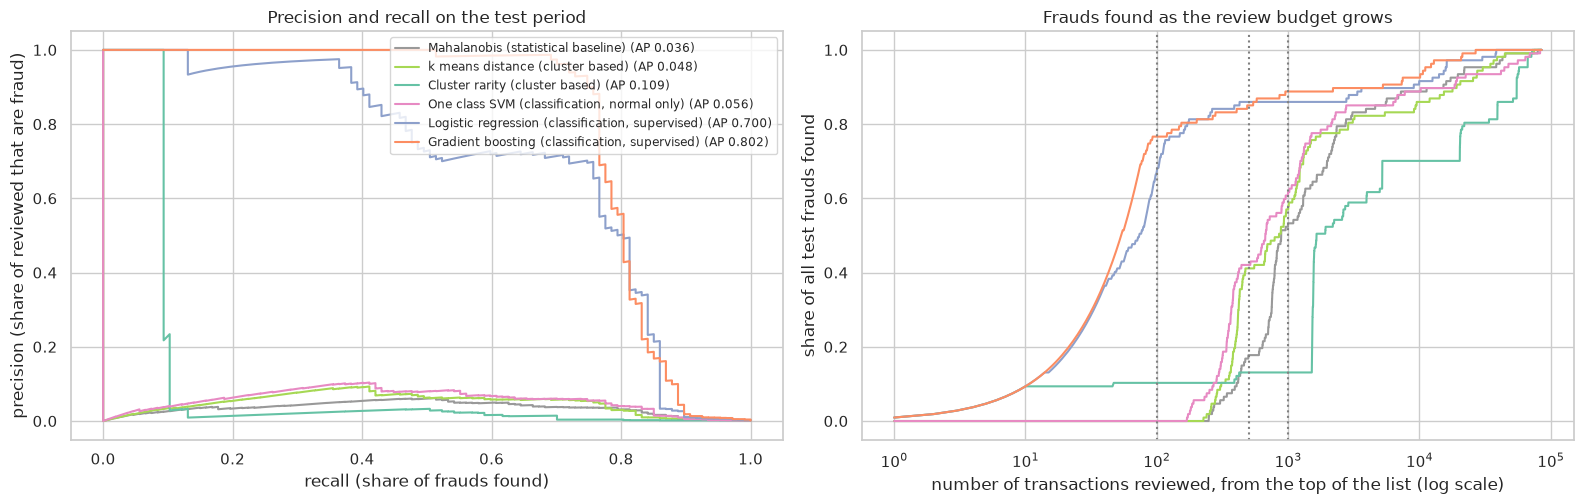

In [19]:
# Plotting precision against recall and the share of frauds found as more transactions are reviewed
main = {"Mahalanobis (statistical baseline)": maha_test,
        "k means distance (cluster based)": nearest_dist,
        "Cluster rarity (cluster based)": rarity,
        "One class SVM (classification, normal only)": ocsvm_scores,
        "Logistic regression (classification, supervised)": logit_scores,
        "Gradient boosting (classification, supervised)": gb_scores}
colours = ["#999999", "#a6d854", "#66c2a5", "#e78ac3", "#8da0cb", "#fc8d62"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for (name, s), col in zip(main.items(), colours):
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[0].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_test, s):.3f})", color=col)
    order = np.argsort(-s, kind="stable")
    found = np.cumsum(y_test[order]) / y_test.sum()
    axes[1].plot(np.arange(1, len(s) + 1), found, color=col, label=name)
axes[0].set(xlabel="recall (share of frauds found)", ylabel="precision (share of reviewed that are fraud)",
            title="Precision and recall on the test period")
axes[0].legend(fontsize=8.5, loc="upper right")
axes[1].set(xscale="log", xlabel="number of transactions reviewed, from the top of the list (log scale)",
            ylabel="share of all test frauds found", title="Frauds found as the review budget grows")
for b in [100, 500, 1000]:
    axes[1].axvline(b, ls=":", c="grey")
plt.tight_layout(); plt.show()

In [20]:
# Bootstrapping the test period 500 times to put uncertainty bands around AP and the gaps between methods
boot = {n: [] for n in main}
for _ in range(500):
    idx = rng.integers(0, len(y_test), len(y_test))
    for n, s in main.items():
        boot[n].append(average_precision_score(y_test[idx], s[idx]))
boot = pd.DataFrame(boot)
ci = pd.DataFrame({"AP": [average_precision_score(y_test, s) for s in main.values()],
                   "lower 2.5%": boot.quantile(0.025), "upper 97.5%": boot.quantile(0.975)}, index=list(main))
print(ci.round(3))

names = list(main)
pairs = [(names[5], names[4]), (names[4], names[3]), (names[3], names[2]), (names[2], names[1]), (names[1], names[0])]
gaps = pd.DataFrame({f"{a.split(' (')[0]} minus {b.split(' (')[0]}": boot[a] - boot[b] for a, b in pairs})
print("\nBootstrap distribution of AP differences")
print(pd.DataFrame({"mean": gaps.mean(), "lower 2.5%": gaps.quantile(0.025), "upper 97.5%": gaps.quantile(0.975),
                    "share above zero": (gaps > 0).mean()}).round(3))

                                                     AP  lower 2.5%  upper 97.5%
Mahalanobis (statistical baseline)                0.036       0.027        0.047
k means distance (cluster based)                  0.048       0.036        0.063
Cluster rarity (cluster based)                    0.109       0.059        0.176
One class SVM (classification, normal only)       0.056       0.042        0.075
Logistic regression (classification, supervised)  0.700       0.616        0.780
Gradient boosting (classification, supervised)    0.802       0.726        0.870

Bootstrap distribution of AP differences
                                              mean  lower 2.5%  upper 97.5%  share above zero
Gradient boosting minus Logistic regression  0.101       0.051        0.155             1.000
Logistic regression minus One class SVM      0.642       0.567        0.711             1.000
One class SVM minus Cluster rarity          -0.053      -0.113       -0.006             0.014
Cluster rarity 

The comparison is decisive.

The methods that do not learn from fraud labels (the statistical baseline, the cluster based scores and the one class SVM) all have an AP of about 0.11 or less. The distance based ones reach a ROC AUC of 0.94 to 0.95, so they do push frauds towards the top half of the list overall, but none of them has a single fraud in its top 100, and an investigator using them would spend the first hundred reviews entirely on legitimate customers. Cluster rarity is the exception at the very top, with 11 frauds in its top 100, but it finds almost nothing beyond that.

The supervised classifiers are in a different league. Gradient boosting reaches an AP of about 0.8 and logistic regression about 0.7. Gradient boosting places around 80 frauds in its top 100, so four in five reviews find real fraud, and its top 1,000 contains most of the frauds in the test period. The bootstrap intervals for the supervised and unsupervised methods do not come close to overlapping.

Between the two supervised models, gradient boosting has the higher AP (about 0.80 against 0.70) and is ahead in every bootstrap resample, because it can capture the nonlinear, threshold like patterns in V17, V14 and the other separating components. Logistic regression is not far behind and is easier to explain to an investigator.

Among the methods that do not use fraud labels, cluster rarity is ahead of the k means distance in 99.6 percent of resamples and ahead of the one class SVM in about 99 percent, although its bootstrap interval is wide (about 0.06 to 0.18) because its success rests on a small number of frauds in one cluster. The k means distance is a small but consistent improvement on the Mahalanobis baseline. The one class SVM, which knows which training transactions were normal but has never seen fraud, sits between the distance scores and cluster rarity.

### 2.5 Sensitivity checks

In [21]:
# Check 1: how much does the cluster based result depend on the number of clusters?
k_rows = []
for k, model in km_models.items():
    s = model.transform(X_test).min(axis=1)
    r = rarity_score(model, model.labels_, X_test)
    k_rows.append({"k": k, "distance AP": average_precision_score(y_test, s),
                   "distance frauds in top 100": int(y_test[np.argsort(-s)[:100]].sum()),
                   "rarity AP": average_precision_score(y_test, r),
                   "rarity frauds in top 100": int(y_test[np.argsort(-r, kind="stable")[:100]].sum()),
                   "smallest cluster share": (np.bincount(model.labels_) / len(model.labels_)).min()})
pd.DataFrame(k_rows).set_index("k").round(4)

,distance AP,distance frauds in top 100,rarity AP,rarity frauds in top 100,smallest cluster share
k,,,,,
2,0.0401,0,0.0112,0,0.4182
3,0.0401,0,0.0017,0,0.1567
4,0.0402,0,0.0150,0,0.1013
5,0.0392,0,0.1390,13,0.0011
6,0.0452,0,0.1237,13,0.0011
8,0.0484,0,0.1261,14,0.0011
10,0.0412,0,0.1269,13,0.0011
12,0.0491,0,0.1264,14,0.0011
15,0.0479,0,0.1093,11,0.0011


The distance score is insensitive to k, staying between about 0.04 and 0.06 and never finding a fraud in its top 100. The rarity score is just as steady once k is at least 5 (AP between about 0.10 and 0.14, with 11 to 14 frauds in the top 100), because from k = 5 onward k means always isolates the same tiny fraud rich cluster (the smallest cluster share stays at 0.11 percent). With 2 to 4 clusters there is no small cluster, and the rarity score fails completely, as the definition of a cluster based outlier would predict. So the rarity result is not a lucky choice of k. Note that I chose k with the silhouette and not with this table, because choosing k by test AP would quietly use the labels.

In [22]:
# Check 2: a random stratified split instead of the time ordered split, refitting the main methods
tr_r, te_r = train_test_split(df, test_size=0.3, stratify=df["Class"], random_state=RANDOM_STATE)
sc_r = StandardScaler().fit(tr_r[features])
A, B = sc_r.transform(tr_r[features]), sc_r.transform(te_r[features])
ya, yb = tr_r["Class"].to_numpy(), te_r["Class"].to_numpy()
d = B - A.mean(axis=0)
km_r = KMeans(n_clusters=best_k, n_init=5, random_state=RANDOM_STATE).fit(A)
rand_rows = [
    ranking_report("Mahalanobis", np.einsum("ij,jk,ik->i", d, np.linalg.pinv(np.cov(A, rowvar=False)), d), yb),
    ranking_report("k means distance", km_r.transform(B).min(axis=1), yb),
    ranking_report("Cluster rarity", rarity_score(km_r, km_r.labels_, B), yb),
    ranking_report("Logistic regression", clone(logit_search.best_estimator_).fit(A, ya).predict_proba(B)[:, 1], yb),
    ranking_report("Gradient boosting", clone(gb_search.best_estimator_).fit(A, ya).predict_proba(B)[:, 1], yb),
]
print("Test frauds in the random split:", int(yb.sum()))
pd.DataFrame(rand_rows).set_index("method").round(4)

Test frauds in the random split: 142


,AP,ROC AUC,frauds in top 100,recall at 100,frauds in top 500,recall at 500,frauds in top 1000,recall at 1000
method,,,,,,,,
Mahalanobis,0.1173,0.9484,25,0.1761,54,0.3803,84,0.5915
k means distance,0.0708,0.9481,6,0.0423,54,0.3803,90,0.6338
Cluster rarity,0.4149,0.8133,63,0.4437,65,0.4577,66,0.4648
Logistic regression,0.7081,0.9651,84,0.5915,119,0.8380,121,0.8521
Gradient boosting,0.8190,0.9740,97,0.6831,121,0.8521,126,0.8873


With a random split the test set has more frauds (142 against 107), so the counts in the top 100, 500 and 1,000 are not directly comparable, but the AP is. Two things stand out.

The supervised models barely change (AP about 0.71 and 0.82 against 0.70 and 0.80), so their advantage does not depend on how the data was split.

The unsupervised scores, however, look far better on a random split. Cluster rarity jumps from an AP of about 0.11 to about 0.41, with 63 frauds in its top 100, and the Mahalanobis baseline triples to about 0.12. A random split mixes the two days, so the fraud pattern that dominated the earlier period is present in the test set too. This shows that the unsupervised detectors are excellent at spotting a fraud campaign that is under way, but that their performance depends heavily on whether the current fraud looks like a rare, tight group. It also shows why I chose the time ordered split for the main comparison: a random split would have flattered the unsupervised methods with a pattern that, in reality, was already fading.

In [23]:
# Check 3: does adding the hour of the day help the supervised model?
feat_h = features + ["hour_of_day"]
sc_h = StandardScaler().fit(train[feat_h])
gb_h = clone(gb_search.best_estimator_).fit(sc_h.transform(train[feat_h]), y_train)
hour_row = ranking_report("Gradient boosting with hour of day", gb_h.predict_proba(sc_h.transform(test[feat_h]))[:, 1])
pd.DataFrame([results_table.loc["Classification based: gradient boosting"].rename(None).to_dict() | {"method": "Gradient boosting without hour"},
              hour_row]).set_index("method").round(4)

,AP,ROC AUC,frauds in top 100,recall at 100,frauds in top 500,recall at 500,frauds in top 1000,recall at 1000
method,,,,,,,,
Gradient boosting without hour,0.8022,0.9834,82.0,0.7664,91.0,0.8505,95.0,0.8879
Gradient boosting with hour of day,0.7939,0.9838,82.0,0.7664,91.0,0.8505,92.0,0.8598


Adding the hour of the day changes the results only slightly. Although fraud is far more common at night, the night time pattern seems to be captured already by the V features, or there are too few nights (only two) in the data to learn a reliable time pattern. I am leaving it out of the main model.

In [24]:
# Check 4: how many labelled frauds does the supervised approach need? Retraining with a random subset of training frauds
fraud_idx, normal_idx = np.where(y_train == 1)[0], np.where(y_train == 0)[0]
label_rows = []
for n_fraud in [10, 25, 50, 100, 200, len(fraud_idx)]:
    aps = []
    for rep in range(3):
        r = np.random.default_rng(rep)
        keep = np.concatenate([normal_idx, r.choice(fraud_idx, n_fraud, replace=False)])
        model = clone(logit_search.best_estimator_).fit(X_train[keep], y_train[keep])
        aps.append(average_precision_score(y_test, model.predict_proba(X_test)[:, 1]))
    label_rows.append({"labelled frauds used for training": n_fraud, "mean AP (3 repeats)": np.mean(aps),
                       "lowest AP": np.min(aps)})
label_table = pd.DataFrame(label_rows).set_index("labelled frauds used for training")
label_table["best unsupervised AP"] = results_table.loc[[r for r in results_table.index if not r.startswith(("Classification based: logistic", "Classification based: gradient"))], "AP"].max()
label_table.round(3)

,mean AP (3 repeats),lowest AP,best unsupervised AP
labelled frauds used for training,,,
10,0.687,0.638,0.109
25,0.593,0.539,0.109
50,0.539,0.487,0.109
100,0.586,0.562,0.109
200,0.642,0.617,0.109
366,0.700,0.700,0.109


This check explains when each kind of approach makes sense. Even with only 10 labelled frauds, logistic regression reaches an AP of about 0.64 to 0.69, six times the best method that does not use fraud labels, and it stays well above it at every size tried. The curve is not smooth: with 25 to 100 frauds the AP dips to about 0.5 to 0.6 before rising again to 0.70 with all 366. My reading is that with so few examples, which particular frauds are drawn matters more than how many, and the frauds from the early attack pattern can pull the model towards a pattern that later fades. Even so, labelled history is extremely valuable, so whenever a card company has it, a classification based ranking should be the backbone of the queue. The case for a cluster based or other unsupervised detector rests on something else: catching new kinds of fraud that do not resemble any labelled example, which this two day test period cannot fully measure.

In [25]:
# Check 5: are there frauds that the unsupervised method ranks highly but the supervised model misses?
top_n = 1000
gb_top = set(np.argsort(-gb_scores)[:top_n])
km_top = set(np.argsort(-rarity, kind="stable")[:top_n])
fraud_rows = set(np.where(y_test == 1)[0])
print(f"Test frauds: {len(fraud_rows)}")
print(f"Found in gradient boosting top {top_n}:  {len(fraud_rows & gb_top)}")
print(f"Found in cluster rarity top {top_n}:     {len(fraud_rows & km_top)}")
print(f"Found by cluster rarity but missed by gradient boosting: {len(fraud_rows & (km_top - gb_top))}")
print(f"Missed by both:                           {len(fraud_rows - gb_top - km_top)}")

Test frauds: 107
Found in gradient boosting top 1000:  95
Found in cluster rarity top 1000:     14
Found by cluster rarity but missed by gradient boosting: 1
Missed by both:                           11


At a budget of 1,000, the cluster rarity detector finds only one fraud that gradient boosting misses, and 11 frauds are missed by both. In this test period the supervised model already covers nearly everything the cluster based detector finds. The argument for keeping an unsupervised detector alongside it therefore rests on what this short dataset cannot test: a genuinely new fraud pattern that the supervised model has never seen. The fraud rich cluster shows that such patterns do form tight, rare groups that clustering can pick up without labels, so a rarity alarm is a sensible, cheap safeguard rather than a proven gain.

### 2.6 Choice of approach

For ranking transactions for investigation, I recommend the classification based approach with gradient boosting as the main ranking, with logistic regression as a simpler fallback. Gradient boosting puts 82 frauds in its top 100 against at most 11 for any method that does not use fraud labels, and its AP is about seven times higher than the best of them.

The cluster based approach, scored by cluster rarity, is the right tool when no labels exist, for example for a new product or market. Its ability to isolate a fraud pattern without labels makes it worth keeping as a secondary alarm, with its rare clusters reviewed regularly by an analyst. Its scores should not drive the main investigation queue on their own, because in the test period it found few frauds beyond the single pattern it had isolated.

## Part 3. Why an unusual transaction is not necessarily fraudulent

Anomaly detection rests on an assumption: that what is rare is also what is bad. This dataset shows clearly where that assumption breaks down.

### 3.1 The most unusual transactions are legitimate

In [26]:
# Looking at the 100 most unusual test transactions according to the statistical baseline
top100 = np.argsort(-maha_test)[:100]
print("Frauds among the 100 most unusual test transactions:", int(y_test[top100].sum()))
print("Their median amount:", round(test["Amount"].iloc[top100].median(), 2), "euros, against",
      round(test["Amount"].median(), 2), "euros for all test transactions")
print("Share of them above the 99th percentile of amount:",
      round((test["Amount"].iloc[top100] > test["Amount"].quantile(0.99)).mean(), 2))

# Which features make them extreme? Counting how often each feature is the most extreme one (largest absolute z)
most_extreme = pd.Series(np.array(features)[np.abs(X_test[top100]).argmax(axis=1)]).value_counts().head(8)
most_extreme.to_frame("number of top 100 transactions where this is the most extreme feature")

Frauds among the 100 most unusual test transactions: 0
Their median amount: 538.36 euros, against 20.0 euros for all test transactions
Share of them above the 99th percentile of amount: 0.43


,number of top 100 transactions where this is the most extreme feature
V28,31
V23,25
V20,16
V8,8
V7,6
V2,4
V27,4
V5,4


None of the 100 most statistically unusual transactions in the test period is fraud. They are unusual for other reasons, such as very large legitimate payments or extreme values on low variance components, where a small absolute change produces a large z score once the feature is standardised. In everyday terms these are the equivalent of a customer buying a holiday, paying a large bill, or using their card in an unusual way. They are rare, but they are not crimes.

### 3.2 Many frauds are not unusual at all

frauds in the most unusual 1 percent     0.477
frauds in the most unusual 10 percent    0.888
frauds in the less unusual half          0.028


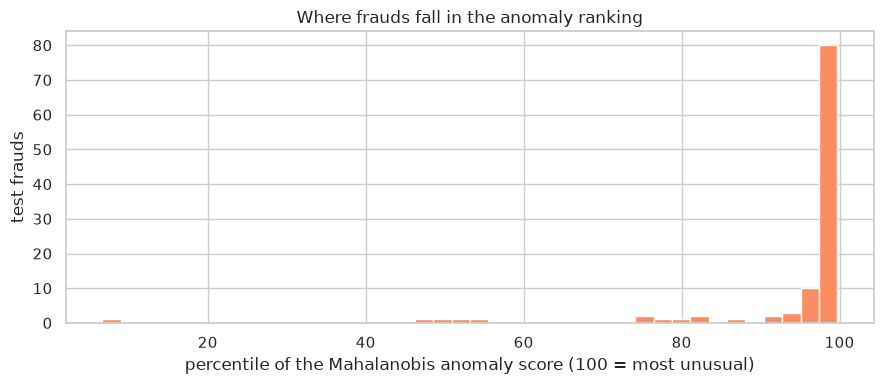

In [27]:
# Locating each test fraud within the anomaly ranking: what percentile of unusualness does it reach?
pct = stats.rankdata(maha_test) / len(maha_test)
fraud_pct = pct[y_test == 1]
summary_pct = pd.Series({
    "frauds in the most unusual 1 percent": (fraud_pct >= 0.99).mean(),
    "frauds in the most unusual 10 percent": (fraud_pct >= 0.90).mean(),
    "frauds in the less unusual half": (fraud_pct < 0.50).mean(),
})
print(summary_pct.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(fraud_pct * 100, bins=40, color="#fc8d62")
ax.set(xlabel="percentile of the Mahalanobis anomaly score (100 = most unusual)", ylabel="test frauds",
       title="Where frauds fall in the anomaly ranking")
plt.tight_layout(); plt.show()

Most frauds are indeed more unusual than average, which is why the ROC AUC is high: about 48 percent of test frauds fall in the most unusual 1 percent of transactions, and about 89 percent in the most unusual 10 percent. But that leaves about one fraud in nine outside the most unusual tenth, and three frauds (about 3 percent) sit in the less unusual half of all transactions. A fraudster who uses a stolen card for a small, ordinary looking purchase, which the amount analysis in section 1.3 showed is common, produces a transaction that looks normal. Detecting such fraud needs context the data does not contain, such as whether this card has ever been used at this merchant or in this country.

### 3.3 The base rate problem

In [28]:
# Measuring how concentrated fraud is among the most unusual transactions, compared with the overall rate
rows = []
for share in [0.001, 0.01, 0.05]:
    k = int(share * len(y_test))
    top = np.argsort(-maha_test)[:k]
    rows.append({"most unusual share reviewed": share, "transactions": k, "fraud rate among them": y_test[top].mean(),
                 "times the overall rate": y_test[top].mean() / y_test.mean(),
                 "share of them that are legitimate": 1 - y_test[top].mean()})
pd.DataFrame(rows).round(4)

,most unusual share reviewed,transactions,fraud rate among them,times the overall rate,share of them that are legitimate
0,0.001,85,0.0000,0.0000,1.0000
1,0.010,851,0.0599,47.6736,0.9401
2,0.050,4255,0.0212,16.8260,0.9788


Even where the anomaly score does concentrate fraud, the large majority of flagged transactions are still legitimate. In the most unusual 1 percent of test transactions, fraud is about 48 times more common than average, yet 94 percent of those transactions are legitimate. In the most unusual 5 percent the figure is 98 percent. In the most unusual 0.1 percent, every single one is legitimate. This is the base rate problem described by Bolton and Hand (2002) in their review of statistical fraud detection. When only about one transaction in 600 is fraudulent, even a score that makes fraud far more likely among flagged transactions still leaves legitimate customers in the majority. Being unusual raises the probability of fraud without making fraud the most likely explanation.

### 3.4 Summary

An unusual transaction is not necessarily fraudulent, for five connected reasons, each visible in this data.

1. Legitimate behaviour is varied. People make large purchases, travel, buy from new merchants and change their habits. These are rare events, but they are legitimate, and they fill the top of a pure anomaly ranking (section 3.1).
2. Fraud is often designed to look normal. Fraudsters test cards with small amounts and imitate ordinary spending to avoid attention (section 1.3), so many frauds are not statistical outliers at all (section 3.2).
3. "Unusual" depends on the features and the model. A transaction is only unusual relative to what the model can see. Here the features are anonymised principal components with no customer history, so a purchase that is ordinary for one customer and alarming for another looks identical. Some features, once standardised, turn tiny differences into large scores.
4. Fraud is rare. Because of the base rate, even a score that strongly concentrates fraud flags far more legitimate transactions than fraudulent ones (section 3.3).
5. The labels are imperfect. The "normal" class includes any fraud that was never detected or reported, and the fraud class reflects past investigation choices. An unusual transaction labelled normal may be undetected fraud, and a normal looking one may be labelled fraud.

The practical consequence is that an anomaly score should be used to prioritise human review, not to accuse customers or automatically block their cards. A false alarm has real costs: a declined payment, an anxious phone call, and lost trust. The supervised ranking reduces those costs greatly by learning what fraud actually looks like, but every alert still needs a human or a further check before action is taken, and the system should be monitored and retrained as both legitimate behaviour and fraud tactics change.

## References

Bolton, R. J. and Hand, D. J. (2002). Statistical fraud detection: a review. Statistical Science, 17(3), 235 to 255.

Chandola, V., Banerjee, A. and Kumar, V. (2009). Anomaly detection: a survey. ACM Computing Surveys, 41(3), article 15.

Dal Pozzolo, A., Caelen, O., Johnson, R. A. and Bontempi, G. (2015). Calibrating probability with undersampling for unbalanced classification. IEEE Symposium Series on Computational Intelligence (SSCI), 159 to 166. Source of the credit card dataset.

Han, J., Kamber, M. and Pei, J. (2011). Data Mining: Concepts and Techniques (3rd edition), chapter 12, Outlier Detection. Morgan Kaufmann.

He, Z., Xu, X. and Deng, S. (2003). Discovering cluster based local outliers. Pattern Recognition Letters, 24(9 and 10), 1641 to 1650.

Mahalanobis, P. C. (1936). On the generalised distance in statistics. Proceedings of the National Institute of Sciences of India, 2(1), 49 to 55.

Pedregosa, F. and colleagues (2011). Scikit learn: machine learning in Python. Journal of Machine Learning Research, 12, 2825 to 2830.

Rousseeuw, P. J. and Van Driessen, K. (1999). A fast algorithm for the minimum covariance determinant estimator. Technometrics, 41(3), 212 to 223.

Saito, T. and Rehmsmeier, M. (2015). The precision recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. PLOS ONE, 10(3), e0118432.

Schölkopf, B., Platt, J. C., Shawe Taylor, J., Smola, A. J. and Williamson, R. C. (2001). Estimating the support of a high dimensional distribution. Neural Computation, 13(7), 1443 to 1471.